# Robot Kolu: Kazayla mı Çarptı, İnsan Bilerek mi Dokundu?

İnsanla aynı alanda çalışan bir robot kolu, bir temasın kazara çarpışma mı yoksa operatörün bilinçli bir müdahalesi mi olduğunu ayırt edebilmelidir. İlk durumda durması, ikincisinde çalışmaya devam etmesi gerekir. Bu çalışmada KUKA LWR4+ robot kolunun yedi eklemindeki dış tork sinyallerinden temas türü sınıflandırıldı. Karar ağacı modeli test verisinde %97,3 doğruluğa ulaştı; çarpışmaların yaklaşık %4–7'sini ise kaçırdı.

Veri: Zenodo 6461868 (TU Münih, CC BY 4.0) | Araçlar: Python, Pandas, NumPy, Matplotlib, scikit-learn

## Aşama 1: Problem Tanımı ve Proje Planı

### 1.1 Proje Tanım Formu

| | |
|---|---|
| Alan | Endüstriyel robotik, insan-robot iş birliği güvenliği |
| Problem | Robot kolunun 7 eklemindeki tork sinyallerinden (1,024 sn'lik pencere), olayın kazara çarpışma, kasıtlı insan teması ya da serbest hareket olduğunu tahmin etmek |
| Hedef değişken (y) | `sinif` (kategorik): `cls` kazara çarpışma, `ctc` kasıtlı temas, `fre` serbest hareket |
| Özellikler (X) | Her eklemin sinyalinden 5 özet değer: taban, tepe, yükseliş, zirve süresi, temas sonrası ortalama (7 × 5 = 35 özellik) |
| Problem türü | Çok sınıflı sınıflandırma (3 sınıf) |

### 1.2 Gerekçe

İş birlikçi robotlar (cobot) fabrikalarda insanlarla aynı alanı paylaşıyor ve bir temas algıladıklarında doğru tepkiyi vermeleri gerekiyor. Kazara bir çarpışmada durmayan robot operatörü yaralayabilir. Operatörün robotu bilerek yönlendirdiği bir temasta duran robot ise gereksiz duruşa ve üretim kaybına yol açar. Bu iki durumu yalnızca robotun kendi eklem tork sensörleriyle, ek kamera ya da dokunma sensörü kullanmadan ayırt edebilen bir model, robot üreticileri ve fabrika güvenlik mühendisleri için daha güvenli ve daha verimli bir iş birliği sağlar. Robotla çalışan operatörler de hem daha güvende olur hem de gereksiz duruşlarla karşılaşmaz.

## Aşama 2: Veri Toplama ve Hazırlama

### 2.1 Kütüphaneler ve sabitler

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import os
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

plt.rcParams.update({
    "figure.figsize": (8, 5),   # varsayılan grafik boyutu (genişlik, yükseklik), inç
    "axes.titlesize": 13,       # grafik başlığının yazı boyutu
    "axes.labelsize": 11,       # eksen etiketlerinin yazı boyutu
    "axes.grid": True,          # arka plana ızgara çiz
    "grid.alpha": 0.3,          # ızgara saydamlığı (0 = görünmez, 1 = koyu)
})

# Sınıf renkleri ve adları: her grafikte aynı sınıf aynı renk ve adla görünsün
SINIF_RENK = {"cls": "#C44E52", "ctc": "#4C72B0", "fre": "#55A868"}
SINIF_AD   = {"cls": "Kazara çarpışma", "ctc": "Kasıtlı temas", "fre": "Serbest hareket"}

SINIFLAR = ["cls", "ctc", "fre"]   # sınıf kodları; grafik ve tablolarda hep bu sırayla
EKLEMLER = range(1, 8)             # eklem numaraları: 1, 2, ..., 7
TEMAS    = 256                     # temasın başladığı an (ms); 2.3'teki grafiklerde doğrulandı
t_ms     = np.arange(1024)         # bir pencerenin zaman ekseni: 0, 1, ..., 1023 ms


### 2.2 Verinin indirilmesi

Veri seti Zenodo'dan (kayıt 6461868) indirildi: üç sınıf ve yedi eklem için 21 CSV dosyası ile bir açıklama dosyası. Her dosyanın boyutu, kaynakta bildirilen boyutla karşılaştırılarak doğrulandı.

In [14]:
KAYIT_NO = "6461868"                 # Zenodo kayıt numarası (veri setinin kimliği)
KLASOR   = "veri"                    # dosyaları bu klasöre indireceğiz
os.makedirs(KLASOR, exist_ok=True)   # klasörü oluştur (zaten varsa hata verme)

yanit = requests.get(f"https://zenodo.org/api/records/{KAYIT_NO}")
yanit.raise_for_status()             # istek başarısızsa burada dur
dosyalar = yanit.json()["files"]
print(f"Dosya sayısı: {len(dosyalar)} | Toplam: {sum(d['size'] for d in dosyalar) / 1e9:.2f} GB\n")

for d in dosyalar:
    ad, yol = d["key"], os.path.join(KLASOR, d["key"])

    # Dosya yoksa ya da eksik inmişse indir (tam olanları atla)
    if not (os.path.exists(yol) and os.path.getsize(yol) == d["size"]):
        url = f"https://zenodo.org/records/{KAYIT_NO}/files/{ad}?download=1"
        with requests.get(url, stream=True) as r:                       # stream: parça parça al
            r.raise_for_status()
            with open(yol, "wb") as f:
                for parca in r.iter_content(chunk_size=1024 * 1024):    # 1 MB'lık parçalar
                    f.write(parca)

    # İnen dosyanın boyutu Zenodo'nun bildirdiğiyle aynı mı?
    durum = "tamam" if os.path.getsize(yol) == d["size"] else "BOYUT UYUŞMUYOR!"
    print(f"{ad:<18} {d['size'] / 1e6:7.1f} MB  {durum}")

Dosya sayısı: 22 | Toplam: 3.69 GB

fre-joint-3.csv      258.7 MB  tamam
cls-joint-1.csv      128.0 MB  tamam
cls-joint-3.csv      127.9 MB  tamam
fre-joint-5.csv      263.4 MB  tamam
ctc-joint-4.csv      137.0 MB  tamam
ReadMe.md              0.0 MB  tamam
cls-joint-5.csv      129.8 MB  tamam
ctc-joint-1.csv      137.1 MB  tamam
ctc-joint-5.csv      139.7 MB  tamam
fre-joint-2.csv      256.6 MB  tamam
cls-joint-4.csv      128.6 MB  tamam
ctc-joint-6.csv      138.0 MB  tamam
cls-joint-7.csv      129.6 MB  tamam
fre-joint-4.csv      260.8 MB  tamam
fre-joint-7.csv      262.1 MB  tamam
ctc-joint-3.csv      137.1 MB  tamam
ctc-joint-7.csv      140.4 MB  tamam
fre-joint-6.csv      260.1 MB  tamam
ctc-joint-2.csv      135.2 MB  tamam
fre-joint-1.csv      260.7 MB  tamam
cls-joint-2.csv      126.5 MB  tamam
cls-joint-6.csv      128.3 MB  tamam


### 2.3 Okuma ve ilk inceleme

Her dosya başlıksız bir matristir: Her satır 1,024 saniyelik bir pencereyi, her sütun bir milisaniyedeki dış torku (Nm) gösterir. Temas her pencerede 256. milisaniyede başlar. Önce tek bir dosyanın yapısı incelendi, ardından 21 dosyanın tamamı belleğe alındı.

In [15]:
with open(os.path.join(KLASOR, "ReadMe.md"), encoding="utf-8") as f:
    print(f.read())

### Naming of the .csv files
The name of each .csv file contains three parts:
- **'cls'**/**'ctc'**/**'fre'** indicates the classes：****accidental collisions****, ****intentional contacts****, or ****contact free****;
- **joint** means that the signals are the external torques measured by the robot joint torque sensors;
- **1 .. 7** indicates the number of the joint.

### Format of the .csv files
Each file contains an **N** by **M** matrix with delimiter **','**. **M** = 1024 is the length of the signals (1.024s with sampling rate 1kHz). **N** is the number of signal pieces, with **N** = 6960 for **'cls'**, **N** = 7583 for **'ctc'**, and **N** = 14098 for **'fre'**.

### Import and plot the signals in Python
#### Import data using the 'csv' module

```
  import csv
  import numpy as np
  
  with open('cls-joint-1.csv', newline='') as csv_file:
    data = np.array(list(csv.reader(csv_file, delimiter=","))).astype("float")
    print(np.shape(data))
```
  
#### Import data using Pandas
 

In [16]:
ornek = pd.read_csv(
    os.path.join(KLASOR, "cls-joint-1.csv"),
    header=None,        # dosyada başlık satırı yok, ilk satır da veri
    dtype="float32",    # belleği yarıya indirmek için 4 byte'lık ondalıklı sayı
)

print("Boyut (satır, sütun):", ornek.shape)
print(f"Bellek kullanımı: {ornek.memory_usage().sum() / 1e6:.1f} MB")

ornek.iloc[:5, :8]   # ilk 5 satır, ilk 8 sütun (ilk 8 milisaniye)

Boyut (satır, sütun): (6960, 1024)
Bellek kullanımı: 28.5 MB


,0,1,2,3,4,5,6,7
0,0.231079,0.229508,0.233484,0.229218,0.228613,0.218610,0.205248,0.205918
1,0.664851,0.601832,0.651157,0.655680,0.591174,0.640484,0.627837,0.590728
2,0.025861,0.004856,0.015854,0.004308,0.062601,0.140659,0.206508,0.227092
3,0.075622,0.081900,0.079728,0.083550,0.081771,0.086257,0.081058,0.083457
4,0.491766,0.526911,0.541471,0.551704,0.585189,0.572992,0.652181,0.728867


In [17]:
# 21 dosyanın hepsini oku: anahtar (sinif, eklem), değer (pencere × 1024) NumPy dizisi oluştur
ham = {}
for sinif in SINIFLAR:
    for eklem in EKLEMLER:
        yol = os.path.join(KLASOR, f"{sinif}-joint-{eklem}.csv")
        ham[(sinif, eklem)] = pd.read_csv(yol, header=None, dtype="float32").values
    print(f"{sinif}: 7 eklem okundu")

toplam_mb = sum(dizi.nbytes for dizi in ham.values()) / 1e6
print(f"Toplam bellek: {toplam_mb:.0f} MB")

cls: 7 eklem okundu
ctc: 7 eklem okundu
fre: 7 eklem okundu
Toplam bellek: 821 MB


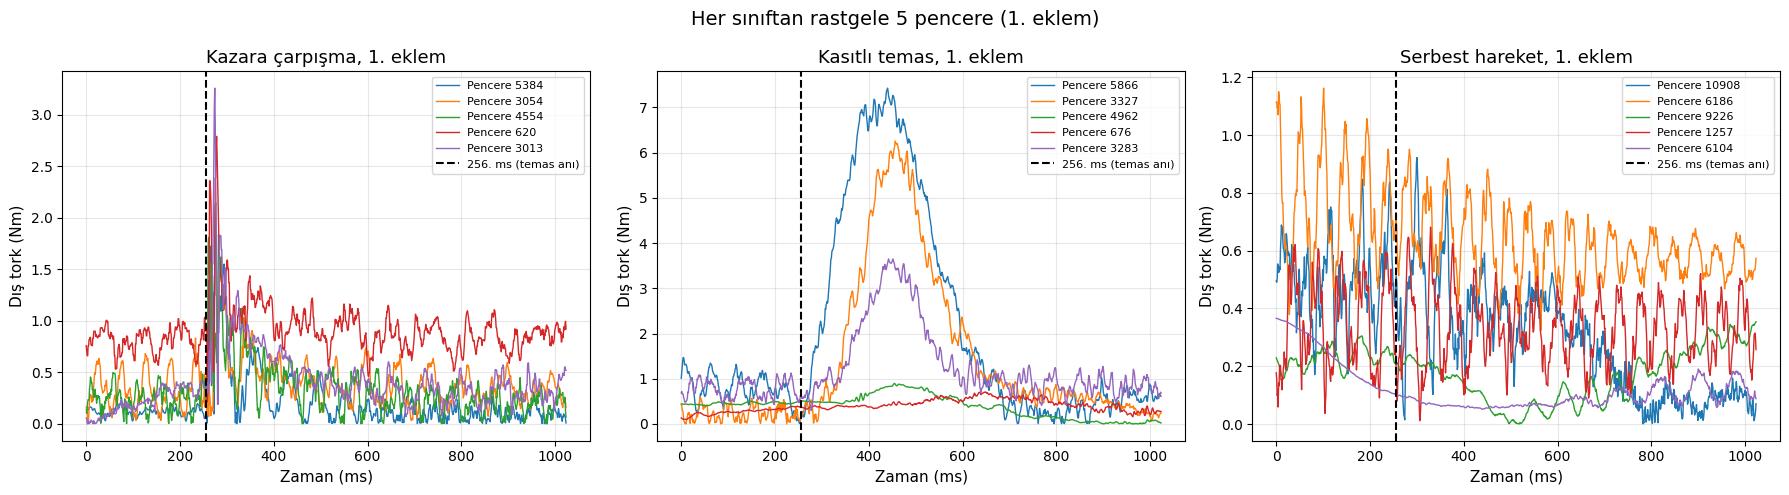

In [18]:
# Her sınıftan rastgele 5 pencere (1. eklem): sinyalin şekline ilk bakış
def pencereleri_ciz(ax, sinif, eklem=1, adet=5, tohum=42):
    """ham sözlüğünden bir sınıf-eklem dizisinin rastgele 'adet' penceresini verilen eksene çizer."""
    veri = ham[(sinif, eklem)]
    secilen = np.random.default_rng(tohum).choice(len(veri), size=adet, replace=False)
    for i in secilen:
        ax.plot(t_ms, veri[i], linewidth=1, label=f"Pencere {i}")
    ax.axvline(TEMAS, color="black", linestyle="--", label=f"{TEMAS}. ms (temas anı)")
    ax.set_title(f"{SINIF_AD[sinif]}, {eklem}. eklem")
    ax.set_xlabel("Zaman (ms)")
    ax.set_ylabel("Dış tork (Nm)")
    ax.legend(fontsize=8)

fig, eksenler = plt.subplots(1, 3, figsize=(18, 5))
for ax, sinif in zip(eksenler, SINIFLAR):
    pencereleri_ciz(ax, sinif)
fig.suptitle("Her sınıftan rastgele 5 pencere (1. eklem)", fontsize=14)
plt.tight_layout()
plt.show()

Rastgele seçilen pencerelerde üç sınıfın farklı davrandığı görülüyor. Çarpışmada tork temastan hemen sonra keskin biçimde yükselip yaklaşık 100 ms içinde sönüyor. Kasıtlı temasta daha yavaş yükselen ve uzun süren bir tepe oluşuyor. Serbest harekette belirgin bir yükselme yok. Bazı temaslar 1. eklemde neredeyse hiç görünmediği için yedi eklemin tamamı kullanıldı. Bu gözlemler Aşama 3'te tüm veriyle doğrulandı.

### 2.4 Veri kalitesi

Eksik ve sonsuz değerler, hiç değişmeyen (donmuş sensör) pencereler, değer aralığı, kopya pencereler ve eklem dosyalarının satır satır aynı olaya ait olup olmadığı kontrol edildi.

In [19]:
# Temel kalite kontrolleri: boyut, eksik değer, düz pencere, değer aralığı

# 1) Her sınıfta 7 eklemin satır sayısı aynı mı?
for sinif in SINIFLAR:
    satirlar = [ham[(sinif, e)].shape[0] for e in EKLEMLER]
    print(f"{sinif}: eklem başına satır sayısı = {satirlar}")

# 2) Eksik (NaN) ve sonsuz (inf) değer sayısı
nan_toplam = sum(pd.isnull(d).sum() for d in ham.values())
inf_toplam = sum(np.isinf(d).sum() for d in ham.values())
print(f"\nEksik değer (NaN): {nan_toplam} | Sonsuz değer (inf): {inf_toplam}")

# 3) Düz pencere (donmuş sensör): 1024 değerin hepsi aynıysa standart sapma 0 olur
duz = sum(int((d.std(axis=1) == 0).sum()) for d in ham.values())
print(f"Düz pencere sayısı (std = 0): {duz}")

# 4) Değer aralığı: negatif değer var mı?
en_kucuk = min(d.min() for d in ham.values())
en_buyuk = max(d.max() for d in ham.values())
negatif  = sum((d < 0).sum() for d in ham.values())
print(f"En küçük: {en_kucuk:.4f} Nm | En büyük: {en_buyuk:.2f} Nm | Negatif değer sayısı: {negatif}")

cls: eklem başına satır sayısı = [6960, 6960, 6960, 6960, 6960, 6960, 6960]
ctc: eklem başına satır sayısı = [7583, 7583, 7583, 7583, 7583, 7583, 7583]
fre: eklem başına satır sayısı = [14098, 14098, 14098, 14098, 14098, 14098, 14098]

Eksik değer (NaN): 0 | Sonsuz değer (inf): 0
Düz pencere sayısı (std = 0): 0
En küçük: 0.0000 Nm | En büyük: 28.31 Nm | Negatif değer sayısı: 0


In [20]:
# Birebir kopya pencere kontrolü (sınıf içinde ve sınıflar arasında), "parmak izi" (hash) yöntemiyle
def parmak_izleri(d):
    """Her pencerenin (satırın) 1024 değerinden tek bir 'parmak izi' sayısı üretir."""
    return [hash(satir.tobytes()) for satir in d]

for eklem in EKLEMLER:
    izler = {s: parmak_izleri(ham[(s, eklem)]) for s in SINIFLAR}

    # Sınıf içi: toplam pencere sayısı − farklı parmak izi sayısı = kopya sayısı
    ic_kopya = {s: len(iz) - len(set(iz)) for s, iz in izler.items()}

    # Sınıflar arası: iki sınıfta ortak olan parmak izi sayısı
    kumeler = {s: set(iz) for s, iz in izler.items()}
    capraz = (len(kumeler["cls"] & kumeler["ctc"])
              + len(kumeler["cls"] & kumeler["fre"])
              + len(kumeler["ctc"] & kumeler["fre"]))

    print(f"Eklem {eklem}: sınıf içi kopya = {ic_kopya} | sınıflar arası ortak = {capraz}")

Eklem 1: sınıf içi kopya = {'cls': 0, 'ctc': 0, 'fre': 0} | sınıflar arası ortak = 0
Eklem 2: sınıf içi kopya = {'cls': 0, 'ctc': 0, 'fre': 0} | sınıflar arası ortak = 0
Eklem 3: sınıf içi kopya = {'cls': 0, 'ctc': 0, 'fre': 0} | sınıflar arası ortak = 0
Eklem 4: sınıf içi kopya = {'cls': 0, 'ctc': 0, 'fre': 0} | sınıflar arası ortak = 0
Eklem 5: sınıf içi kopya = {'cls': 0, 'ctc': 0, 'fre': 0} | sınıflar arası ortak = 0
Eklem 6: sınıf içi kopya = {'cls': 0, 'ctc': 0, 'fre': 0} | sınıflar arası ortak = 0
Eklem 7: sınıf içi kopya = {'cls': 0, 'ctc': 0, 'fre': 0} | sınıflar arası ortak = 0


In [21]:
# Eklem dosyaları satır satır aynı olaya mı ait? (tepe torkları arasındaki korelasyon, karıştırılmış sırayla karşılaştırma)
rng = np.random.default_rng(42)

for sinif in SINIFLAR:
    # Her pencerenin temas sonrası (256. ms'den itibaren) en yüksek torku, 7 eklem için yan yana
    tepe = np.column_stack([ham[(sinif, e)][:, TEMAS:].max(axis=1) for e in EKLEMLER])   # (satır, 7)
    # 1. eklemin tepesiyle diğer 6 eklemin tepesi arasındaki korelasyon
    gercek  = [np.corrcoef(tepe[:, 0], tepe[:, j])[0, 1] for j in range(1, 7)]
    # Aynısı, ama diğer eklemin satırları karıştırılmış (eşleşme bilerek bozulmuş)
    karisik = [np.corrcoef(tepe[:, 0], rng.permutation(tepe[:, j]))[0, 1] for j in range(1, 7)]

    print(f"{sinif}: gerçek sıra      r (1. eklem ile 2–7) = {np.round(gercek, 2)}")
    print(f"     karıştırılmış sıra r (1. eklem ile 2–7) = {np.round(karisik, 2)}\n")

cls: gerçek sıra      r (1. eklem ile 2–7) = [0.1  0.47 0.2  0.28 0.15 0.08]
     karıştırılmış sıra r (1. eklem ile 2–7) = [ 0.01  0.01  0.02  0.    0.01 -0.  ]

ctc: gerçek sıra      r (1. eklem ile 2–7) = [-0.5   0.34  0.1   0.55  0.25  0.37]
     karıştırılmış sıra r (1. eklem ile 2–7) = [ 0.01  0.   -0.01  0.01 -0.01 -0.  ]

fre: gerçek sıra      r (1. eklem ile 2–7) = [0.21 0.31 0.33 0.13 0.36 0.18]
     karıştırılmış sıra r (1. eklem ile 2–7) = [-0.   -0.    0.01  0.02 -0.02  0.01]



### 2.5 Özellik çıkarımı

Ham sinyal pencere başına 7 × 1024 değer içeriyor. Her eklem için beş özet değer hesaplandı: temas öncesi ortalama (taban), temas sonrası en yüksek değer (tepe), ikisinin farkı (yükseliş), zirvenin temastan kaç ms sonra geldiği (zirve_ms) ve temas sonrası ortalama (sonra_ort). Oluşan tablo Google Drive'a CSV olarak kaydedildi.

In [22]:
# Her pencere için 5 özet özellik çıkaran fonksiyon
def ozellik_cikar(d):
    """d: (pencere × 1024) dizi, tek bir sınıf ve tek bir eklem.
    Her pencere için 5 özellik döndürür (sözlük: özellik adı → değerler dizisi)."""
    once  = d[:, :TEMAS]    # temas öncesi: 0–255 ms
    sonra = d[:, TEMAS:]    # temas sonrası: 256–1023 ms

    taban = once.mean(axis=1)    # temas öncesi ortalama seviye
    tepe  = sonra.max(axis=1)    # temas sonrası en yüksek tork

    return {
        "taban":     taban,
        "tepe":      tepe,
        "yukselis":  tepe - taban,           # tabana göre ne kadar yükseldi
        "zirve_ms":  sonra.argmax(axis=1),   # zirve temastan kaç ms sonra geldi
        "sonra_ort": sonra.mean(axis=1),     # temas sonrası ortalama (süreyi yakalar)
    }

# 21 dosyadan özellik tablosunu kur: her satır = 1 olay, 7 eklem yan yana
parcalar = []
for sinif in SINIFLAR:
    sutunlar = {}
    for eklem in EKLEMLER:
        for ad, degerler in ozellik_cikar(ham[(sinif, eklem)]).items():
            sutunlar[f"eklem{eklem}_{ad}"] = degerler     # ör. "eklem3_tepe"

    parca = pd.DataFrame(sutunlar)
    parca["pencere_no"] = np.arange(len(parca))
    parca["sinif"] = sinif                        # hedef değişken (y)
    parcalar.append(parca)

df = pd.concat(parcalar, ignore_index=True)       # 3 sınıfın tablosunu alt alta birleştir
ozellik_sutunlari = [c for c in df.columns if c.startswith("eklem")]   # 35 özellik (pencere_no ve sinif hariç)

print("Boyut (satır, sütun):", df.shape, "| Özellik sayısı:", len(ozellik_sutunlari))
df.head()

Boyut (satır, sütun): (28641, 37) | Özellik sayısı: 35


,eklem1_taban,eklem1_tepe,eklem1_yukselis,eklem1_zirve_ms,eklem1_sonra_ort,eklem2_taban,eklem2_tepe,eklem2_yukselis,eklem2_zirve_ms,eklem2_sonra_ort,...,eklem6_yukselis,eklem6_zirve_ms,eklem6_sonra_ort,eklem7_taban,eklem7_tepe,eklem7_yukselis,eklem7_zirve_ms,eklem7_sonra_ort,pencere_no,sinif
0,0.206506,0.670691,0.464185,4,0.273842,0.391661,6.754130,6.362469,20,0.920789,...,0.531906,7,0.162548,0.068540,0.572599,0.504059,3,0.064623,0,cls
1,0.709246,1.899245,1.189999,18,0.738988,0.192158,2.964447,2.772290,1,0.491533,...,0.144912,469,0.198855,0.187452,0.314973,0.127522,0,0.142480,1,cls
2,0.188720,2.115962,1.927242,6,0.310843,0.998095,6.368148,5.370052,5,1.384077,...,0.166247,6,1.044841,0.563068,0.738266,0.175198,37,0.552878,2,cls
3,0.201704,0.770556,0.568853,5,0.159033,0.187233,5.831685,5.644452,9,0.496065,...,0.390401,9,0.055221,0.548597,1.338912,0.790316,5,0.512257,3,cls
4,0.680821,4.570896,3.890074,16,1.001253,0.388957,3.133361,2.744404,17,0.269375,...,0.409595,6,0.085922,0.519317,0.667820,0.148503,330,0.592271,4,cls


In [23]:
drive.mount("/content/drive")

CIKTI_KLASOR = "/content/drive/MyDrive/robot_temas_projesi"
os.makedirs(CIKTI_KLASOR, exist_ok=True)
CSV_YOL = os.path.join(CIKTI_KLASOR, "ozellikler.csv")

df.to_csv(CSV_YOL, index=False)   # index=False: satır numaralarını dosyaya yazma
print(f"Kaydedildi: {CSV_YOL} ({os.path.getsize(CSV_YOL) / 1e6:.1f} MB)")

# Kontrol: dosyayı geri oku, aynı boyutta mı?
kontrol = pd.read_csv(CSV_YOL)
print("Geri okunan boyut:", kontrol.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Kaydedildi: /content/drive/MyDrive/robot_temas_projesi/ozellikler.csv (9.4 MB)
Geri okunan boyut: (28641, 37)


### 2.6 Veri sözlüğü

`ozellikler.csv`: 28.641 satır, 37 sütun. Her satır bir pencereye karşılık gelir; `k` eklem numarasıdır (1–7).

| Sütun | Tip | Birim | Açıklama | Rol |
|---|---|---|---|---|
| `eklemk_taban` | Sayısal | Nm | Temas öncesi (0–255 ms) ortalama dış tork | X (Özellik)|
| `eklemk_tepe` | Sayısal | Nm | Temas sonrası (256–1023 ms) en yüksek dış tork | X (Özellik) |
| `eklemk_yukselis` | Sayısal | Nm | Tepe ile taban arasındaki fark | X (Özellik) |
| `eklemk_zirve_ms` | Sayısal (tam sayı) | ms | Zirvenin temastan kaç ms sonra geldiği (0–767) | X (Özellik) |
| `eklemk_sonra_ort` | Sayısal | Nm | Temas sonrası ortalama dış tork | X (Özellik) |
| `pencere_no` | Sayısal (tam sayı) | – | Pencerenin kendi dosyasındaki sıra numarası | Kimlik; modelde kullanılmadı (yalnızca 5.5'teki blok bölme için) |
| `sinif` | Kategorik | – | `cls` kazara çarpışma, `ctc` kasıtlı temas, `fre` serbest hareket |y (Sınıf) |

In [24]:
# Sözlükteki tipler doğru mu? (beklenen: 28 float32, 8 int64, 1 object)
print(df.dtypes.value_counts())   # her veri tipinden kaç sütun var

float32    28
int64       8
object      1
Name: count, dtype: int64


### 2.7 Temizleme ve hazırlama özeti

- Eksik, sonsuz ya da sabit değerli pencere bulunmadı; doldurma veya silme gerekmedi. Kopya pencere de yok.
- Yedi eklem dosyası satır satır aynı olaya ait; eklemler tek tabloda yan yana birleştirildi.
- Tüm değerler sıfır veya pozitif (veri mutlak değer olarak verilmiş); en büyük değer 28,31 Nm.
- Bu nedenle "en düşük tork" ve "aralık" özellik olarak kullanılmadı: İlki her pencerede sıfıra yakın, ikincisi tepe değeriyle aynı bilgiyi taşıyor.
- Hiç satır kaybedilmedi; 28.641 pencerenin tamamı tabloda.
- Sınırlama: `zirve_ms`, temasın her pencerede 256. ms'de başlamasına dayanıyor. Gerçek kullanımda temas anı önceden bilinmez.

## Aşama 3: Keşifçi Veri Analizi (EDA) ve Görselleştirme

### 3.1 Genel özet

Tablonun ilk satırları 2.5'te gösterildi. Burada tablonun boyutu ve her özelliğin özet istatistikleri yer alıyor.

In [25]:
# Boyut ve özet istatistikler (.T: her özellik bir satır olsun)
print("Boyut (satır, sütun):", df.shape)
df.describe().T.round(2)   # .T: tabloyu çevir; her sütun bir satır olsun

Boyut (satır, sütun): (28641, 37)


,count,mean,std,min,25%,50%,75%,max
eklem1_taban,28641.0,0.41,0.30,0.00,0.19,0.35,0.56,8.14
eklem1_tepe,28641.0,2.18,2.78,0.03,0.55,1.06,2.55,21.68
eklem1_yukselis,28641.0,1.77,2.70,-3.10,0.25,0.62,2.11,21.46
eklem1_zirve_ms,28641.0,296.67,267.34,0.00,28.00,248.00,523.00,767.00
eklem1_sonra_ort,28641.0,0.78,1.04,0.01,0.24,0.42,0.80,11.71
eklem2_taban,28641.0,0.66,0.43,0.02,0.35,0.56,0.89,6.94
eklem2_tepe,28641.0,3.43,3.32,0.18,1.20,2.19,4.40,28.31
eklem2_yukselis,28641.0,2.77,3.29,-2.87,0.65,1.31,3.73,27.75
eklem2_zirve_ms,28641.0,298.94,263.26,0.00,26.00,257.00,525.00,767.00
eklem2_sonra_ort,28641.0,1.19,1.22,0.05,0.44,0.76,1.43,11.13


### 3.2 Sınıflara göre farklar

Pencerelerin yaklaşık yarısı (%49,2) serbest hareket sınıfında; bu yüzden her pencereye "serbest hareket" diyen bir model bile %49 doğruluk alır. Medyan tablosu, her özelliğin sınıflar arasında nasıl değiştiğini gösteriyor. Dağılımlar çarpık olduğu için ortalama yerine medyan kullanıldı.

       pencere sayısı  oran (%)
sinif                          
cls              6960      24.3
ctc              7583      26.5
fre             14098      49.2 



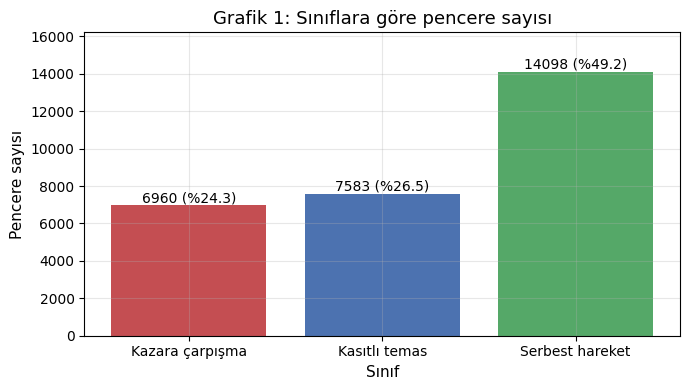

In [26]:
# Sınıf dağılımı: tablo (value_counts) ve Grafik 1
sayilar = df["sinif"].value_counts()[SINIFLAR]                                  # her sınıftan kaç pencere
oranlar = (df["sinif"].value_counts(normalize=True)[SINIFLAR] * 100).round(1)   # yüzde olarak
print(pd.DataFrame({"pencere sayısı": sayilar, "oran (%)": oranlar}), "\n")

plt.figure(figsize=(7, 4))
cubuklar = plt.bar([SINIF_AD[s] for s in SINIFLAR], sayilar, color=[SINIF_RENK[s] for s in SINIFLAR])
plt.bar_label(cubuklar, labels=[f"{sayilar[s]} (%{oranlar[s]})" for s in SINIFLAR])
plt.ylim(0, sayilar.max() * 1.15)

plt.title("Grafik 1: Sınıflara göre pencere sayısı")
plt.xlabel("Sınıf")
plt.ylabel("Pencere sayısı")
plt.tight_layout()
plt.show()

In [27]:
# Sınıflara göre özelliklerin medyanı (groupby): hangi özellik hangi sınıfı ayırıyor?
medyanlar = df.groupby("sinif")[ozellik_sutunlari].median().T[SINIFLAR].round(2)
medyanlar

sinif,cls,ctc,fre
eklem1_taban,0.37,0.44,0.30
eklem1_tepe,1.89,3.87,0.62
eklem1_yukselis,1.51,3.39,0.31
eklem1_zirve_ms,15.00,318.00,398.00
eklem1_sonra_ort,0.40,1.30,0.30
eklem2_taban,0.50,0.64,0.54
eklem2_tepe,3.37,6.25,1.24
eklem2_yukselis,2.78,5.57,0.68
eklem2_zirve_ms,10.00,326.00,411.00
eklem2_sonra_ort,0.62,2.27,0.55


### 3.3 Görselleştirme

Grafik 2, her eklem için sınıfların medyan tork eğrisini ve pencerelerin ortadaki %50'sinin aralığını gösteriyor. Grafik 3'te eklem 2'nin iki özelliği, rastgele seçilen 3.000 pencere üzerinde karşılaştırılıyor.

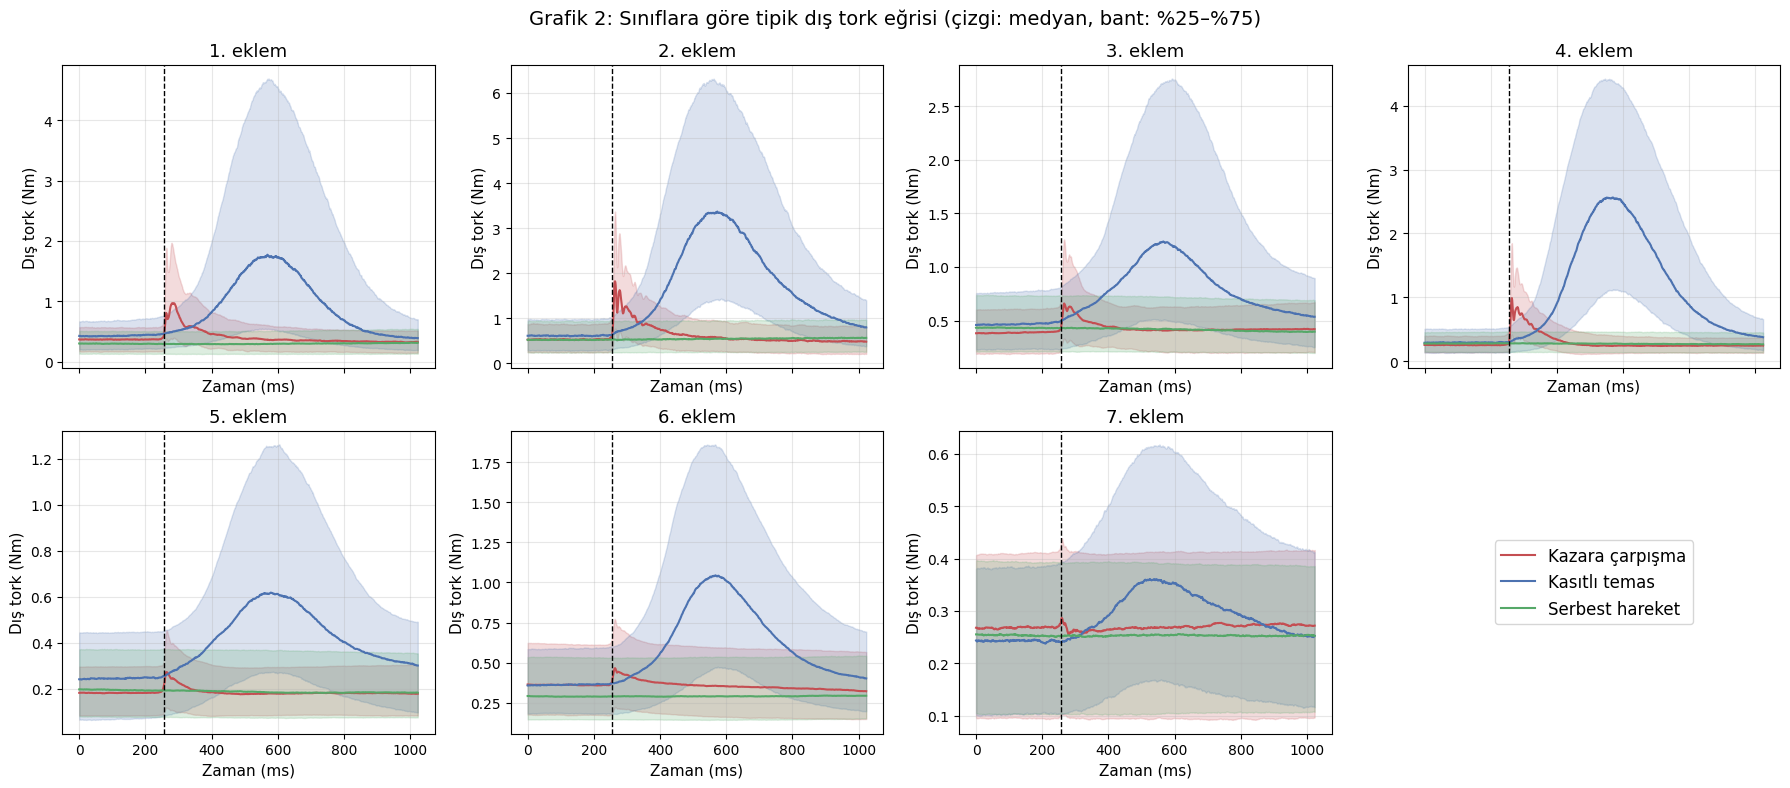

In [28]:
# Grafik 2: Sınıflara göre tipik dış tork eğrisi (7 eklem); çizgi: medyan, bant: %25–%75
fig, eksenler = plt.subplots(2, 4, figsize=(18, 8), sharex=True)
eksenler = eksenler.ravel()

for i, eklem in enumerate(EKLEMLER):
    ax = eksenler[i]
    for sinif in SINIFLAR:
        d = ham[(sinif, eklem)]
        alt, orta, ust = np.percentile(d, [25, 50, 75], axis=0)    # her milisaniye için, pencereler üzerinden
        ax.plot(t_ms, orta, color=SINIF_RENK[sinif], linewidth=1.5, label=SINIF_AD[sinif])
        ax.fill_between(t_ms, alt, ust, color=SINIF_RENK[sinif], alpha=0.2)
    ax.axvline(TEMAS, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"{eklem}. eklem")
    ax.set_xlabel("Zaman (ms)")
    ax.set_ylabel("Dış tork (Nm)")

eksenler[7].axis("off")
eksenler[7].legend(*eksenler[0].get_legend_handles_labels(), loc="center", fontsize=12)
fig.suptitle("Grafik 2: Sınıflara göre tipik dış tork eğrisi (çizgi: medyan, bant: %25–%75)", fontsize=14)
plt.tight_layout()
plt.show()

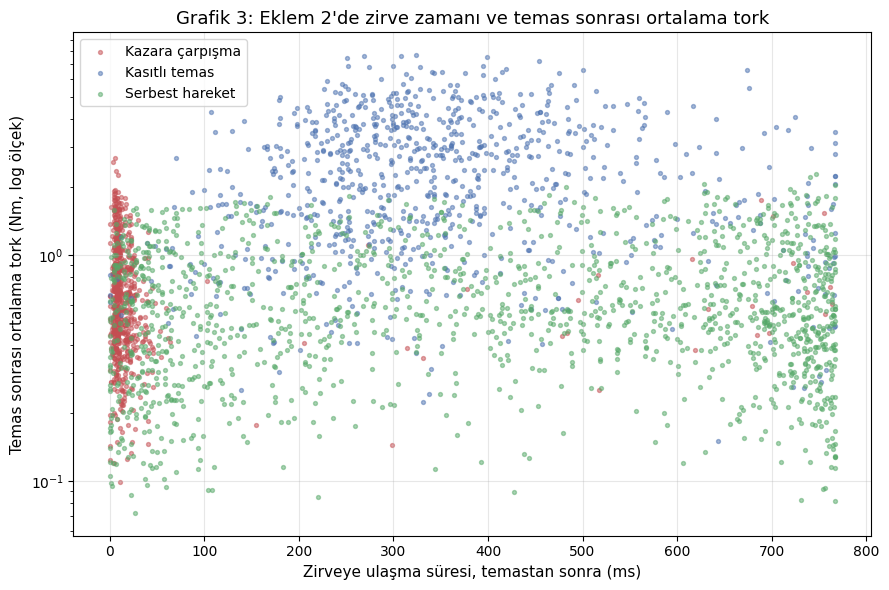

In [29]:
# Grafik 3: Eklem 2'de zirve zamanı ve temas sonrası ortalama tork
ornekler = df.sample(n=3000, random_state=42)   # okunabilirlik için 3.000 rastgele pencere

plt.figure(figsize=(9, 6))
for sinif in SINIFLAR:
    g = ornekler[ornekler["sinif"] == sinif]
    plt.scatter(g["eklem2_zirve_ms"], g["eklem2_sonra_ort"],
                s=8, alpha=0.5, color=SINIF_RENK[sinif], label=SINIF_AD[sinif])

plt.yscale("log")
plt.title("Grafik 3: Eklem 2'de zirve zamanı ve temas sonrası ortalama tork")
plt.xlabel("Zirveye ulaşma süresi, temastan sonra (ms)")
plt.ylabel("Temas sonrası ortalama tork (Nm, log ölçek)")
plt.legend()
plt.tight_layout()
plt.show()

### 3.4 Keşif bulguları

1. Üç sınıfın tork imzası farklı (Grafik 2). Çarpışma temastan hemen sonra yaklaşık 100 ms süren keskin bir sıçrama yapıyor. Kasıtlı temas yavaş yükselen, temastan yaklaşık 320 ms sonra zirve yapan geniş bir tepe çiziyor. Serbest hareket düz kalıyor.
2. Zirve süresi çarpışmayı ayırıyor. Çarpışmalarda medyan 9–16 ms (eklem 7 hariç), diğer iki sınıfta 300 ms'nin üzerinde.
3. Temas sonrası ortalama kasıtlı teması, yükseliş serbest hareketi ayırıyor. Eklem 2'de temas sonrası ortalama kasıtlı temasta 2,27 Nm, diğer sınıflarda 0,6 Nm civarında. Yükseliş serbest harekette 0,68 Nm, çarpışmada 2,78 Nm, kasıtlı temasta 5,57 Nm.
4. Tabana yakın eklemler temasa en güçlü tepkiyi veriyor. En yüksek tork eklem 2'de (omuz) görülüyor; eklem 7 (bilek) çarpışmalara neredeyse hiç tepki vermiyor.
5. Temas öncesi seviye (taban) üç sınıfta benzer ve ayırt edici değil. Zayıf temaslar serbest hareketle, zirvesi temasın hemen başına denk gelen bazı serbest hareket pencereleri çarpışmalarla karışıyor. Çarpışma ile kasıtlı temas ise nadiren karışıyor.

## Aşama 4: Model Kurma ve Eğitme

### 4.1 Özellikler (X) ve hedef (y)

In [30]:
# Özellikleri (X) ve hedefi (y) ayır; pencere_no ve sinif X'e girmemeli (sızıntı kontrolü)
X = df[ozellik_sutunlari]   # 35 özellik (x)
y = df["sinif"]             # hedef (y): cls / ctc / fre

print("X boyutu:", X.shape, "| y boyutu:", y.shape)
print("X'te pencere_no var mı?", "pencere_no" in X.columns)   # sızıntı kontrolü
print("X'te sinif var mı?     ", "sinif" in X.columns)        # hedef X'e girmemeli

X boyutu: (28641, 35) | y boyutu: (28641,)
X'te pencere_no var mı? False
X'te sinif var mı?      False


### 4.2 Eğitim ve test bölmesi

Verinin %80'i eğitim, %20'si test için ayrıldı. Sınıf oranlarının iki kümede de aynı kalması için bölme tabakalı (stratify) yapıldı.

In [31]:
# Veriyi eğitim (%80) ve test (%20) olarak böl; stratify ile sınıf oranları korunuyor
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.20,     # verinin %20'si test
    random_state=42,    # tekrarlanabilir bölme
    stratify=y,         # sınıf oranlarını iki tarafta da koru
)

print("Eğitim:", X_egitim.shape, "| Test:", X_test.shape)

# stratify işe yaradı mı? Sınıf oranlarını karşılaştır
pd.DataFrame({
    "tüm veri (%)": y.value_counts(normalize=True)[SINIFLAR] * 100,
    "eğitim (%)":   y_egitim.value_counts(normalize=True)[SINIFLAR] * 100,
    "test (%)":     y_test.value_counts(normalize=True)[SINIFLAR] * 100,
}).round(1)

Eğitim: (22912, 35) | Test: (5729, 35)


,tüm veri (%),eğitim (%),test (%)
sinif,,,
cls,24.3,24.3,24.3
ctc,26.5,26.5,26.5
fre,49.2,49.2,49.2


### 4.3 Model seçimi

Problem çok sınıflı bir sınıflandırma olduğu için karar ağacı sınıflandırıcısı (DecisionTreeClassifier) kullanıldı. Keşifçi analizde sınıfların büyük ölçüde eşik değerleriyle ayrıldığı görüldü (örneğin zirve süresinin 40 ms'nin altında olması çarpışmaya işaret ediyor); karar ağacı tam olarak bu tür kurallar öğrenir. Kararlarının okunabilir olması güvenlik açısından bir avantaj; ayrıca özelliklerin ölçeklendirilmesini gerektirmez.

### 4.4 Model eğitimi

İlk modelde ağacın derinliği sınırlandırılmadı. Bu model, aşırı öğrenmenin boyutunu görmek için Aşama 5'te referans olarak kullanılıyor.

In [32]:
# İlk deneme: derinlik sınırı olmayan karar ağacı
model = DecisionTreeClassifier(random_state=42)   # ilk deneme: derinlik sınırı yok
model.fit(X_egitim, y_egitim)

print("Ağacın derinliği:", model.get_depth())      # kökten en uzak yaprağa kaç soru var
print("Yaprak sayısı:   ", model.get_n_leaves())   # ağacın kaç farklı "son karar" kutusu var

Ağacın derinliği: 29
Yaprak sayısı:    460


## Aşama 5: Tahmin ve Değerlendirme

### 5.1 İlk modelin doğruluğu

Sınırsız ağacın eğitim ve test doğrulukları, her pencereye "serbest hareket" diyen basit bir referans modelle birlikte veriliyor.

In [33]:
# İlk modelin doğruluğu: eğitim, test ve her şeye "fre" diyen tembel model
y_tahmin = model.predict(X_test)   # test pencereleri için tahminler

test_dogruluk   = accuracy_score(y_test, y_tahmin)
egitim_dogruluk = accuracy_score(y_egitim, model.predict(X_egitim))
tembel_dogruluk = (y_test == "fre").mean()   # her şeye "fre" diyen modelin doğruluğu

print(f"Eğitim doğruluğu          : {egitim_dogruluk:.2%}")
print(f"Test doğruluğu            : {test_dogruluk:.2%}")
print(f"Tembel model (hep 'fre')  : {tembel_dogruluk:.2%}")
print("\nİlk 10 tahmin:", y_tahmin[:10])
print("İlk 10 gerçek:", y_test.values[:10])

Eğitim doğruluğu          : 100.00%
Test doğruluğu            : 96.84%
Tembel model (hep 'fre')  : 49.22%

İlk 10 tahmin: ['fre' 'fre' 'cls' 'ctc' 'fre' 'fre' 'cls' 'fre' 'ctc' 'cls']
İlk 10 gerçek: ['fre' 'fre' 'cls' 'ctc' 'fre' 'fre' 'cls' 'fre' 'ctc' 'cls']


### 5.2 Derinlik seçimi

Ağaç derinliği, eğitim verisinden ayrılan bir doğrulama kümesinde seçildi; test kümesi bu aşamada kullanılmadı. Derinlik arttıkça eğitim doğruluğu sürekli yükseliyor. Doğrulama doğruluğu ise derinlik 8'de en yüksek değerine ulaşıp sonra düşüyor.

In [34]:
# Farklı derinlikleri doğrulama setinde dene (test setine dokunmadan)
X_alt, X_dogr, y_alt, y_dogr = train_test_split(
    X_egitim, y_egitim, test_size=0.20, random_state=42, stratify=y_egitim)

sonuclar = []
for derinlik in [2, 3, 4, 5, 6, 8, 10, 15, 20, None]:   # None = sınır yok
    m = DecisionTreeClassifier(max_depth=derinlik, random_state=42).fit(X_alt, y_alt)
    sonuclar.append({
        "max_depth":     str(derinlik),
        "yaprak":        m.get_n_leaves(),
        "eğitim (%)":    accuracy_score(y_alt,  m.predict(X_alt))  * 100,
        "doğrulama (%)": accuracy_score(y_dogr, m.predict(X_dogr)) * 100,
    })

derinlik_tablosu = pd.DataFrame(sonuclar).round(2)
derinlik_tablosu

,max_depth,yaprak,eğitim (%),doğrulama (%)
0,2,4,93.56,93.08
1,3,8,95.77,94.89
2,4,15,96.63,95.96
3,5,28,97.35,96.84
4,6,45,97.80,97.03
5,8,84,98.54,97.60
6,10,128,98.85,97.40
7,15,215,99.33,97.08
8,20,279,99.60,96.92
9,None,395,100.00,96.51


### 5.3 Son model

Derinliği 8 olan model eğitim kümesinin tamamıyla yeniden eğitildi ve test kümesinde bir kez değerlendirildi.

In [35]:
# Son model: seçilen derinlikle eğitim setinin tamamında eğit, test setinde bir kez ölç
SECILEN_DERINLIK = 8   # Derinlik 5.2'de doğrulama kümesine göre seçildi: 8'de en yüksek (%97,60); daha derin ağaçlarda
# eğitim skoru artarken doğrulama skoru düşüyor, yani model ezberlemeye (aşırı öğrenme) başlıyor.

son_model = DecisionTreeClassifier(max_depth=SECILEN_DERINLIK, random_state=42)
son_model.fit(X_egitim, y_egitim)

# Test setini son modelle BİR KEZ kullanıyoruz
y_tahmin = son_model.predict(X_test)

print(f"Derinlik: {son_model.get_depth()} | Yaprak: {son_model.get_n_leaves()}")
print(f"Eğitim doğruluğu: {accuracy_score(y_egitim, son_model.predict(X_egitim)):.2%}")
print(f"Test doğruluğu  : {accuracy_score(y_test, y_tahmin):.2%}")

Derinlik: 8 | Yaprak: 90
Eğitim doğruluğu: 98.47%
Test doğruluğu  : 97.33%


### 5.4 Karışıklık matrisi

Genel doğruluk hataların türünü göstermez. Güvenlik açısından en önemli ölçü, gerçek çarpışmaların ne kadarının yakalandığıdır (çarpışma sınıfının duyarlılığı, recall).

Kaçırılan çarpışma: 6.9%

                 precision    recall  f1-score   support

Kazara çarpışma      0.980     0.931     0.955      1392
  Kasıtlı temas      0.990     0.980     0.985      1517
Serbest hareket      0.961     0.991     0.976      2820

       accuracy                          0.973      5729
      macro avg      0.977     0.967     0.972      5729
   weighted avg      0.974     0.973     0.973      5729



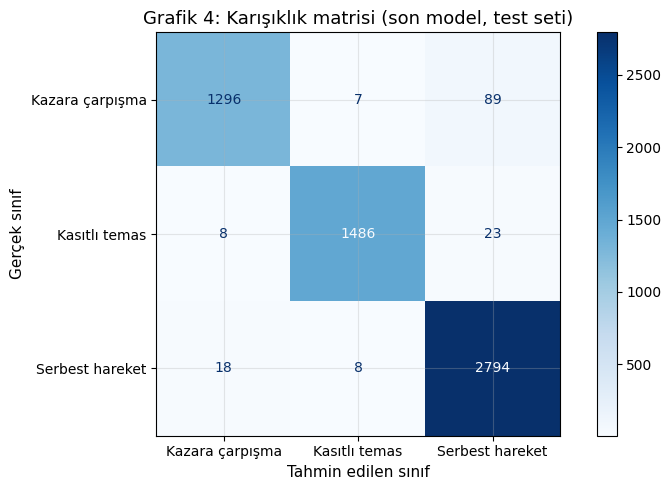

In [36]:
# Karışıklık matrisi ve sınıf bazında başarı (son model, test seti)

def cls_duyarlilik(gercek, tahmin):
    """Gerçek çarpışmaların yüzde kaçı 'cls' olarak yakalandı? (yüksek olsun)"""
    return ((gercek == "cls") & (tahmin == "cls")).sum() / (gercek == "cls").sum()

print(f"Kaçırılan çarpışma: {1 - cls_duyarlilik(y_test, y_tahmin):.1%}\n")

adlar = [SINIF_AD[s] for s in SINIFLAR]
print(classification_report(y_test, y_tahmin, labels=SINIFLAR, target_names=adlar, digits=3))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_tahmin, labels=SINIFLAR, display_labels=adlar, cmap="Blues")
plt.title("Grafik 4: Karışıklık matrisi (son model, test seti)")
plt.xlabel("Tahmin edilen sınıf")
plt.ylabel("Gerçek sınıf")
plt.tight_layout()
plt.show()

### 5.5 Sızıntı kontrolü

Aynı kayıttan gelen benzer pencereler hem eğitim hem test kümesine düşerse skor olduğundan yüksek çıkabilir. Bunu ölçmek için önce ardışık pencerelerin birbirine ne kadar benzediğine bakıldı. Ardından rastgele bölme, her sınıfın ilk %80'iyle eğitilip son %20'siyle test edilen bir modelle (blok bölme) karşılaştırıldı.

In [37]:
# Sızıntı kontrolü:

# 1) Her pencerenin eklem2_tepe değeri, dosyadaki bir sonraki pencereninkiyle ilişkili mi?
rng = np.random.default_rng(42)
for sinif in SINIFLAR:
    t = df.loc[df["sinif"] == sinif, "eklem2_tepe"].values        # bu sınıfın pencereleri, dosyadaki sırayla
    ardisik = np.corrcoef(t[:-1], t[1:])[0, 1]                      # her pencere ile bir sonraki
    karisik = np.corrcoef(t[:-1], rng.permutation(t[1:]))[0, 1]     # referans: sıra bozulmuş
    print(f"{SINIF_AD[sinif]:<16} ardışık r = {ardisik:.2f} | karıştırılmış r = {karisik:.2f}")

# 2) Blok bölme: her sınıfın ilk %80'i eğitim, son %20'si test (komşu pencereler aynı tarafta kalır)
sinif_boyu  = df.groupby("sinif")["pencere_no"].transform("count")   # her satıra kendi sınıfının pencere sayısı
blok_testte = df["pencere_no"] >= 0.8 * sinif_boyu                    # sınıfın son %20'si mi?

Xb_egitim, Xb_test = X[~blok_testte], X[blok_testte]
yb_egitim, yb_test = y[~blok_testte], y[blok_testte]
blok_model = DecisionTreeClassifier(max_depth=SECILEN_DERINLIK, random_state=42).fit(Xb_egitim, yb_egitim)
yb_tahmin  = blok_model.predict(Xb_test)

print(f"\nBlok bölme boyutları: eğitim {Xb_egitim.shape}, test {Xb_test.shape}\n")
print(f"{'':<16}{'doğruluk':>10}{'cls duyarlılığı':>18}")
print(f"{'Rastgele bölme':<16}{accuracy_score(y_test, y_tahmin):>10.2%}{cls_duyarlilik(y_test, y_tahmin):>18.2%}")
print(f"{'Blok bölme':<16}{accuracy_score(yb_test, yb_tahmin):>10.2%}{cls_duyarlilik(yb_test, yb_tahmin):>18.2%}")

Kazara çarpışma  ardışık r = 0.23 | karıştırılmış r = 0.00
Kasıtlı temas    ardışık r = -0.10 | karıştırılmış r = -0.01
Serbest hareket  ardışık r = 0.63 | karıştırılmış r = 0.01

Blok bölme boyutları: eğitim (22914, 35), test (5727, 35)

                  doğruluk   cls duyarlılığı
Rastgele bölme      97.33%            93.10%
Blok bölme          96.25%            96.26%


### 5.6 Yeni örnekler için tahminler

Modelin eğitimde görmediği test kümesinden dört pencere seçildi: Her sınıftan doğru sınıflandırılmış birer örnek ve kaçırılmış bir çarpışma. Güven değeri, pencerenin düştüğü yapraktaki eğitim örneklerinin sınıf oranıdır.

In [38]:
# Test setinden (modelin görmediği) örnekler için tahmin tablosu: her sınıftan 1 doğru + 1 kaçırılan çarpışma
olasiliklar = son_model.predict_proba(X_test)   # her pencere için 3 sınıfın olasılığı

tablo = X_test[["eklem2_yukselis", "eklem2_zirve_ms", "eklem2_sonra_ort"]].copy()
tablo["gerçek"]    = y_test.values
tablo["tahmin"]    = y_tahmin
tablo["güven (%)"] = (olasiliklar.max(axis=1) * 100).round(1)

dogrular = tablo[tablo["gerçek"] == tablo["tahmin"]]
kacirilan = tablo[(tablo["gerçek"] == "cls") & (tablo["tahmin"] == "fre")]

secim = pd.concat(
    [dogrular[dogrular["gerçek"] == s].sample(1, random_state=42) for s in SINIFLAR]   # her sınıftan 1 doğru
    + [kacirilan.sample(1, random_state=42)]                                       # 1 kaçırılan çarpışma
)
secim["gerçek"] = secim["gerçek"].map(SINIF_AD)
secim["tahmin"] = secim["tahmin"].map(SINIF_AD)
secim.round(2)

,eklem2_yukselis,eklem2_zirve_ms,eklem2_sonra_ort,gerçek,tahmin,güven (%)
3637,2.14,26,1.08,Kazara çarpışma,Kazara çarpışma,100.0
7008,5.58,739,2.61,Kasıtlı temas,Kasıtlı temas,99.6
25375,0.59,539,0.62,Serbest hareket,Serbest hareket,96.1
1853,0.80,33,0.36,Kazara çarpışma,Serbest hareket,95.9


Doğru sınıflandırılan üç örnekte değerler kendi sınıflarının tipik düzeyinde ve model %96–100 emin. Kasıtlı temas örneğinde zirve alışılmadık derecede geç (739 ms), ama yüksek yükseliş ve temas sonrası ortalama doğru kararı veriyor. Kaçırılan çarpışmada ise yükseliş yalnızca 0,80 Nm; bu değer çarpışmaların medyanından (2,78 Nm) çok serbest hareketin medyanına (0,68 Nm) yakın. Bu zayıf çarpışma serbest hareketten ayırt edilemiyor ve model yanılırken bile %95,9 emin.

### 5.7 Değerlendirme notu: Model güvenilir mi?

**Başarı.** Son model (karar ağacı, derinlik 8) test kümesinde %97,33 doğruluk aldı; her pencereye "serbest hareket" diyen referans model %49,22'de kalıyor. Kayıt sırasını koruyan blok bölmede doğruluk %96,25.

**Aşırı öğrenme.** Derinliği sınırlanmamış ağaç eğitimde %100, testte %96,84 doğruluk aldı, yani eğitim verisini ezberliyordu. Doğrulama kümesinde seçilen derinlik 8 ile eğitim-test farkı 3,2 puandan 1,1 puana indi, test doğruluğu yükseldi ve ağaç 460 yapraktan 90 yaprağa küçüldü.

**Veri sızıntısı.** Birebir kopya pencere yok, ancak ardışık pencereler birbirine benziyor (serbest harekette r = 0,63). Blok bölmede doğruluk yalnızca 1 puan düştüğü için bu benzerliğin sonuca etkisi küçük. Veride kayıt kimliği bulunmadığı için tam kayıt bazlı bir bölme yapılamadı.

**Zayıf yön.** Çarpışmaların %93,1'i yakalandı (blok bölmede %96,3), yani yaklaşık %4–7'si kaçırılıyor. Kaçırılan 96 çarpışmanın 89'u serbest hareket olarak sınıflandırıldı. Bunlar torku çok az yükselen zayıf çarpışmalar; model bu pencerelerde yanılırken bile %95'in üzerinde emin olabiliyor. Çarpışma ile kasıtlı temasın karıştırılması ise çok nadir (5.729 test penceresinde 15).

**Sınırlamalar.** Zirve süresi, temasın her pencerede 256. ms'de başladığı varsayımına dayanıyor. Gerçek bir robotta temas anı bilinmediği için performans muhtemelen daha düşük olur. Ayrıca veri tek bir robottan (KUKA LWR4+) ve tek bir laboratuvardan geliyor ve yalnızca tork sinyali içeriyor.

**Sonuç.** Model bu veri setinde üç sınıfı güvenilir biçimde ayırıyor ve aşırı öğrenme kontrol altında. Ancak çarpışmaların bir kısmını kaçırdığı ve temas anının bilinmediği koşullarda denenmediği için tek başına bir güvenlik sistemi olarak yeterli değil.

**Olası iyileştirmeler.** Çarpışmayı kaçırmanın daha ağır cezalandırılması (`class_weight`), temas anını varsaymayan bir kayan pencere yaklaşımı, zayıf çarpışmaları ayırt edebilecek yeni özellikler ve modelin başka bir robotun (ör. Franka Panda) verisinde denenmesi.

## Aşama 6: Akıllı Tahmin Aracı (Mini Uygulama)

### 6.1 Aralığa göre temas tahmini (`tahmin_et`)

Kullanıcıdan eklem seçmesi istenmez; her test penceresi için en güçlü tepkiyi veren eklemin tepe torku ve zirve süresi kullanılır. Kullanıcının verdiği aralığa düşen test pencereleri son modelle sınıflandırılır ve en sık tahmin edilen sınıf sonuç olarak döndürülür. Bu pencerelerin gerçek sınıfları bilindiği için modelin o aralıktaki doğruluğu da raporlanır.

In [39]:
# Hazırlık: her test penceresi için en güçlü tepki veren eklemi, onun tepe torkunu ve zirve süresini bul
tepe_sutunlari  = [f"eklem{e}_tepe" for e in EKLEMLER]
zirve_sutunlari = [f"eklem{e}_zirve_ms" for e in EKLEMLER]

tepeler     = X_test[tepe_sutunlari].values
en_guclu    = tepeler.argmax(axis=1)
genel_tepe  = tepeler.max(axis=1)
genel_zirve = X_test[zirve_sutunlari].values[np.arange(len(X_test)), en_guclu]

# Rehber: her sınıfta tipik aralık (%10 – %90); kullanıcıya önerilen örnek aralıklar buradan
rehber = pd.DataFrame({"tork (Nm)": genel_tepe, "zirve (ms)": genel_zirve, "sinif": y_test.values})
print(rehber.groupby("sinif")[["tork (Nm)", "zirve (ms)"]].quantile([0.10, 0.90]).round(1), "\n")

KARAR = {"cls": "Robot DURDURULMALI!", "ctc": "İş birliğine devam.", "fre": "Temas yok, harekete devam."}

def tahmin_et(tork_min, tork_max, zirve_min, zirve_max):
    """En güçlü eklemdeki tepe tork ve zirve süresi verilen aralıkta olan test pencerelerini
    ana modelle (son_model) sınıflandırır ve sonucu bir cümleyle döndürür."""
    tork_min, tork_max = sorted([tork_min, tork_max])      # sınırlar ters girilirse düzelt
    zirve_min, zirve_max = sorted([zirve_min, zirve_max])
    secim = ((genel_tepe >= tork_min) & (genel_tepe <= tork_max)
             & (genel_zirve >= zirve_min) & (genel_zirve <= zirve_max))
    if secim.sum() == 0:
        return "Bu aralıkta pencere bulunamadı, aralığı genişletin."

    tahminler = son_model.predict(X_test[secim])
    sonuc     = pd.Series(tahminler).mode()[0]
    dogruluk  = (tahminler == y_test.values[secim]).mean()
    eklem     = pd.Series(en_guclu[secim] + 1).mode()[0]

    return (f"Tork {tork_min}–{tork_max} Nm, zirve {zirve_min}–{zirve_max} ms "
            f"→ {SINIF_AD[sonuc]} ({secim.sum()} pencereden {(tahminler == sonuc).sum()} tanesi). {KARAR[sonuc]}\n"
            f"   En güçlü tepki çoğunlukla {eklem}. eklemde. "
            f"[Kontrol: model bu pencerelerde %{dogruluk * 100:.0f} doğru]")

# Örnek çalıştırmalar (aralıklar yukarıdaki rehberden)
print(tahmin_et(2, 6.5, 0, 35))      # çarpışma aralığı
print(tahmin_et(5, 14, 190, 560))    # kasıtlı temas aralığı
print(tahmin_et(0.9, 2.5, 50, 740))  # serbest hareket aralığı
print(tahmin_et(1.5, 2.5, 0, 35))    # zor bölge: zayıf çarpışma mı, serbest hareket mi?

           tork (Nm)  zirve (ms)
sinif                           
cls   0.1        1.9         4.0
      0.9        6.5        34.0
ctc   0.1        4.8       188.0
      0.9       13.7       560.4
fre   0.1        0.9        33.0
      0.9        2.5       741.0 

Tork 2–6.5 Nm, zirve 0–35 ms → Kazara çarpışma (1081 pencereden 1011 tanesi). Robot DURDURULMALI!
   En güçlü tepki çoğunlukla 2. eklemde. [Kontrol: model bu pencerelerde %98 doğru]
Tork 5–14 Nm, zirve 190–560 ms → Kasıtlı temas (959 pencereden 958 tanesi). İş birliğine devam.
   En güçlü tepki çoğunlukla 2. eklemde. [Kontrol: model bu pencerelerde %100 doğru]
Tork 0.9–2.5 Nm, zirve 50–740 ms → Serbest hareket (1706 pencereden 1675 tanesi). Temas yok, harekete devam.
   En güçlü tepki çoğunlukla 2. eklemde. [Kontrol: model bu pencerelerde %98 doğru]
Tork 1.5–2.5 Nm, zirve 0–35 ms → Kazara çarpışma (274 pencereden 169 tanesi). Robot DURDURULMALI!
   En güçlü tepki çoğunlukla 2. eklemde. [Kontrol: model bu pencerelerde %89 doğ

### 6.2 Kullanıcı girdisi

Tork ve zirve süresi için birer aralık girilir. Önerilen örnek aralıklar 6.1'deki tablodan alındı.

In [40]:

# Mini uygulama: kullanıcıdan tork ve zirve süresi aralığı al, tahmin et
print("Robot kolunda ölçülen en yüksek tork ve zirve süresi için birer aralık girin.")
print("Örnek: çarpışma ≈ 2–6.5 Nm & 0–35 ms | temas ≈ 5–14 Nm & 190–560 ms | serbest ≈ 0.9–2.5 Nm & 50–740 ms\n")

tork_min  = float(input("En yüksek tork, alt sınır (Nm): "))
tork_max  = float(input("En yüksek tork, üst sınır (Nm): "))
zirve_min = float(input("Zirve süresi, alt sınır (ms): "))
zirve_max = float(input("Zirve süresi, üst sınır (ms): "))

print("\n" + tahmin_et(tork_min, tork_max, zirve_min, zirve_max))


Robot kolunda ölçülen en yüksek tork ve zirve süresi için birer aralık girin.
Örnek: çarpışma ≈ 2–6.5 Nm & 0–35 ms | temas ≈ 5–14 Nm & 190–560 ms | serbest ≈ 0.9–2.5 Nm & 50–740 ms

En yüksek tork, alt sınır (Nm): 7
En yüksek tork, üst sınır (Nm): 9
Zirve süresi, alt sınır (ms): 150
Zirve süresi, üst sınır (ms): 200

Tork 7.0–9.0 Nm, zirve 150.0–200.0 ms → Kasıtlı temas (23 pencereden 23 tanesi). İş birliğine devam.
   En güçlü tepki çoğunlukla 2. eklemde. [Kontrol: model bu pencerelerde %100 doğru]


## Aşama 7: Dokümantasyon

### Sonuç özeti

- **Problem:** Robot kolunun eklem torklarından temas türünü (kazara çarpışma, kasıtlı temas, serbest hareket) tahmin ederek robotun durması mı, çalışmaya devam etmesi mi gerektiğine karar vermek.
- **Veri:** KUKA LWR4+ robotundan 28.641 pencere (1,024 sn, 1 kHz); eklem başına 5 özet değer, toplam 35 özellik.
- **Yöntem:** Karar ağacı. Derinlik doğrulama kümesinde seçildi (8); test kümesi yalnızca son değerlendirmede kullanıldı.
- **Sonuç:** Test doğruluğu %97,33 (referans model %49), blok bölmede %96,25. Çarpışma ile kasıtlı temas nadiren karışıyor.
- **Çıkarım:** Model bu veri setinde güvenilir, ancak çarpışmaların %4–7'sini kaçırıyor ve temas anının bilindiğini varsayıyor; tek başına bir güvenlik sistemi için yeterli değil.

### Teslim dosyaları

- Sunum (3–5 slayt)
- Proje raporu (1 sayfa)
- Bu not defteri